# Lima: dengue emergente (hipótesis H3)

Lima quedó fuera del modelo principal: el 96 % de sus casos de 2010–2024 son de 2023–2024, y antes de 2021 nunca pasó de 362 casos al año. Es justo el tipo de **periodo atípico** de la hipótesis H3 de la guía: *el desempeño es peor en periodos atípicos que en años típicos*.

Este notebook responde tres preguntas:

1. **¿Cómo emergió el dengue en Lima?** Casos por año, por provincia y por distrito.
2. **¿Qué pasó con el clima?** Anomalías de temperatura en las semanas de 2023–2024 frente a 2010–2022, y el ICEN durante El Niño costero de 2023.
3. **¿Se podía pronosticar?** Para 2023 y 2024, con 2 semanas de anticipación, se comparan:
   - **Persistencia.**
   - **XGBoost entrenado solo con la historia de Lima** (casi no tiene ejemplos).
   - **XGBoost entrenado con los departamentos de la costa** (Piura, Tumbes, Lambayeque, La Libertad, Ica y Áncash), que sí conocen el dengue. Se prueba sin y con clima. Como el modelo aprende el **cambio** semanal (objetivo "delta"), puede aplicarse a otro departamento aunque su nivel de casos sea distinto.

Todo con la misma regla que los demás notebooks: para pronosticar el año *Y* solo se usan años anteriores.

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

from modelado import (MAX_ARBOLES, N_REZAGOS, REJILLA, a_casos, candidatas, marcar_brotes, metricas,
                      modelo_xgb, objetivo_de, preparar_panel, seleccionar, umbral_brote)

PROC, INTERIM, OUT = ROOT / "data" / "processed", ROOT / "data" / "interim", ROOT / "outputs"
LIMA = "LIMA"
COSTA = ["PIURA", "TUMBES", "LAMBAYEQUE", "LA LIBERTAD", "ICA", "ANCASH"]
H = 2
ANIOS_EVALUADOS = [2023, 2024]
REJILLA_DELTA = [c for c in REJILLA if c["objetivo"] == "delta"]

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
TINTA, TINTA_2, REJ = "#0b0b0b", "#52514e", "#e1e0d9"


def estilo(ax):
    ax.grid(color=REJ, lw=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

## 1. Cómo emergió el dengue en Lima

In [3]:
casos = pd.read_parquet(INTERIM / "casos_limpios.parquet", columns=["ubigeo", "provincia", "distrito", "ano"])
lima = casos[casos["ubigeo"].str[:2] == "15"]
por_anio = lima.groupby("ano").size()
print("Casos de Lima por ano:")
print(por_anio.loc[2010:].to_string())
recientes = lima[lima["ano"] >= 2023]
print(f"\n2023-2024: {len(recientes):,} casos = {len(recientes) / len(lima[lima['ano'] >= 2010]):.0%} de 2010-2024")
print(f"Lima Metropolitana (provincia 1501): {(recientes['ubigeo'].str[:4] == '1501').mean():.0%} de los casos 2023-2024")
print("\nDistritos con mas casos en 2023-2024:")
print(recientes.groupby("distrito").size().sort_values(ascending=False).head(10).to_string())
anios_con_casos = lima[lima["ano"] >= 2010].groupby("distrito")["ano"].min()
print(f"\nDistritos de Lima con casos por primera vez (desde 2010) en 2023 o 2024: "
      f"{(anios_con_casos >= 2023).sum()} de {len(anios_con_casos)}")

Casos de Lima por ano:
ano
2010       90
2012      314
2013      102
2014        4
2015        9
2016       58
2017      362
2018       11
2019       46
2020      350
2021     1190
2022      938
2023    30735
2024    87864

2023-2024: 118,599 casos = 97% de 2010-2024
Lima Metropolitana (provincia 1501): 86% de los casos 2023-2024

Distritos con mas casos en 2023-2024:
distrito
COMAS                      13328
SAN JUAN DE LURIGANCHO     13169
CARABAYLLO                  7508
INDEPENDENCIA               7053
PUENTE PIEDRA               6920
VILLA MARIA DEL TRIUNFO     6172
ATE                         6126
SAN MARTIN DE PORRES        5806
SAN JUAN DE MIRAFLORES      4956
LURIGANCHO                  4793

Distritos de Lima con casos por primera vez (desde 2010) en 2023 o 2024: 36 de 79


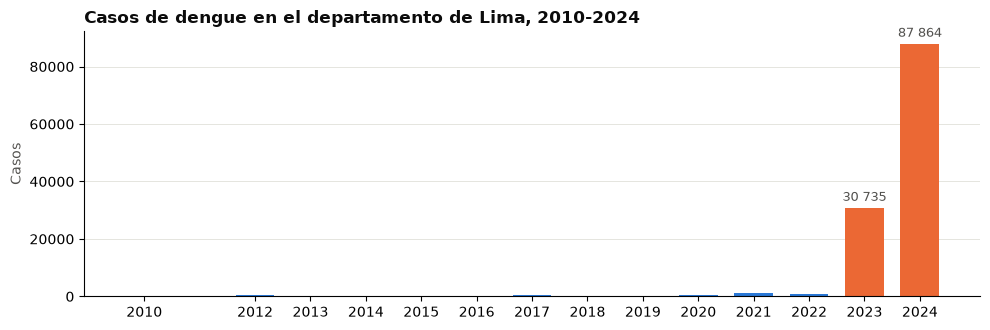

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
serie = por_anio.loc[2010:]
ax.bar(serie.index, serie.values, color=[NARANJA if a >= 2023 else AZUL for a in serie.index], width=0.7)
for a, v in serie.loc[2023:].items():
    ax.annotate(f"{v:,}".replace(",", " "), (a, v), ha="center", va="bottom", fontsize=9, color=TINTA_2,
                xytext=(0, 3), textcoords="offset points")
ax.set_xticks(serie.index)
ax.set_ylabel("Casos", color=TINTA_2)
ax.set_title("Casos de dengue en el departamento de Lima, 2010-2024", loc="left", fontsize=12,
             fontweight="bold", color=TINTA)
estilo(ax)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "lima_casos_por_anio.png", dpi=120)
plt.show()

## 2. Clima en 2023–2024

El clima de Lima en el panel está ponderado por los casos de 2010–2021, así que representa la zona de Lima Metropolitana donde ocurren los casos. La anomalía de cada semana se calcula contra la media de **la misma semana en 2010–2022**, es decir, solo con años anteriores.

In [5]:
panel = preparar_panel(pd.read_parquet(PROC / "panel_depto_semana.parquet"))
pl = panel[panel["departamento"] == LIMA].copy()
ref = pl[pl["ano"] <= 2022].groupby(pl["semana"].clip(upper=52))[["temp_media", "temp_min", "hum_rel", "precip_total"]].mean()
for v in ["temp_media", "temp_min", "hum_rel", "precip_total"]:
    pl[f"{v}_anom"] = pl[v] - pl["semana"].clip(upper=52).map(ref[v])
resumen = pl.groupby("ano")[["temp_media_anom", "temp_min_anom", "hum_rel_anom", "icen_lag3"]].mean().loc[2018:]
print("Anomalia media anual frente a 2010-2022 (misma semana) e ICEN medio de 3 meses antes:")
print(resumen.round(2).to_string())
verano = pl[pl["semana"].between(1, 20)].groupby("ano")["temp_media_anom"].mean().loc[2018:]
print("\nAnomalia de temperatura media en las semanas 1-20 (verano y otono):")
print(verano.round(2).to_string())

Anomalia media anual frente a 2010-2022 (misma semana) e ICEN medio de 3 meses antes:
      temp_media_anom  temp_min_anom  hum_rel_anom  icen_lag3
ano                                                          
2018            -0.09          -0.03          0.62      -0.87
2019             0.35           0.30         -0.16       0.10
2020             0.17           0.13         -0.55      -0.45
2021            -0.21          -0.14         -0.10      -0.69
2022            -0.70          -0.77         -0.97      -1.22
2023             1.05           1.29          3.47       1.20
2024             0.63           0.78          0.98       0.39

Anomalia de temperatura media en las semanas 1-20 (verano y otono):
ano
2018   -0.40
2019    0.53
2020    0.46
2021   -0.31
2022   -0.91
2023    0.39
2024    0.87


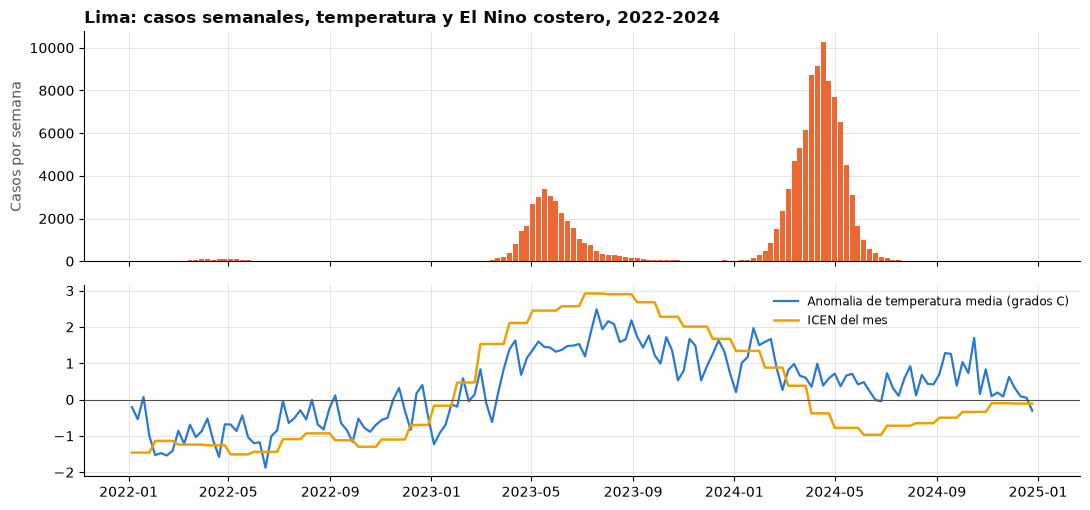

In [6]:
v = pl[pl["ano"] >= 2022]
fig, ejes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ejes[0].bar(v["fecha"], v["casos"], width=6, color=NARANJA)
ejes[0].set_ylabel("Casos por semana", color=TINTA_2)
ejes[0].set_title("Lima: casos semanales, temperatura y El Nino costero, 2022-2024", loc="left",
                  fontsize=12, fontweight="bold", color=TINTA)
ejes[1].plot(v["fecha"], v["temp_media_anom"], color=AZUL, lw=1.6, label="Anomalia de temperatura media (grados C)")
ejes[1].plot(v["fecha"], v["icen"], color=AMARILLO, lw=1.8, label="ICEN del mes")
ejes[1].axhline(0, color=TINTA_2, lw=0.8)
ejes[1].legend(loc="upper right", frameon=False, fontsize=8.5)
for ax in ejes:
    estilo(ax)
fig.tight_layout()
fig.savefig(OUT / "lima_clima_2022_2024.png", dpi=120)
plt.show()

## 3. ¿Se podía pronosticar? (H3)

Para cada año evaluado *Y* (2023 y 2024):

| Modelo | Con qué se entrena (años ≤ *Y* − 1) |
|---|---|
| Persistencia | Repite los casos de *T* − 2 |
| XGBoost solo Lima | Historia de Lima |
| XGBoost costa, sin clima | Los 6 departamentos de la costa, con casos rezagados y estacionalidad |
| XGBoost costa, con clima | Igual, más el clima seleccionado por categoría con los datos de la costa |

Los hiperparámetros se eligen con el año *Y* − 1 como validación, igual que en el notebook 11.

In [7]:
def ajustar(datos, cols, anio):
    """Elige la configuracion con el ano anterior y reentrena con todo hasta el ano anterior."""
    tr = datos[datos["ano"] <= anio - 2].dropna(subset=cols)
    va = datos[datos["ano"] == anio - 1].dropna(subset=cols)
    final = datos[datos["ano"] <= anio - 1].dropna(subset=cols)
    mejor = None
    for config in REJILLA_DELTA:
        m = modelo_xgb(config, MAX_ARBOLES, parada=True)
        m.fit(tr[cols], objetivo_de(config, tr, H), eval_set=[(va[cols], objetivo_de(config, va, H))], verbose=False)
        mae = mean_absolute_error(va["casos"], a_casos(config, m.predict(va[cols]), va, H))
        if mejor is None or mae < mejor[0]:
            mejor = (mae, config, m.best_iteration + 1)
    _, config, n = mejor
    modelo = modelo_xgb(config, n, parada=False)
    modelo.fit(final[cols], objetivo_de(config, final, H), verbose=False)
    return lambda df: a_casos(config, modelo.predict(df[cols]), df, H)


base = [f"casos_l{k}" for k in range(H, H + N_REZAGOS)] + ["sem_sin", "sem_cos"]
costa = panel[panel["departamento"].isin(COSTA)]
resultados = []
for anio in ANIOS_EVALUADOS:
    ev = pl[pl["ano"] == anio]
    clima, sel = seleccionar(costa[costa["ano"] <= anio - 2].dropna(subset=base), candidatas(H, H + N_REZAGOS - 1))
    preds = {
        "Persistencia": np.expm1(ev[f"casos_l{H}"].to_numpy()),
        "XGBoost solo Lima": ajustar(pl, base, anio)(ev),
        "XGBoost costa, sin clima": ajustar(costa, base, anio)(ev),
        "XGBoost costa, con clima": ajustar(costa, base + clima, anio)(ev),
    }
    print(f"{anio}: clima seleccionado con la costa: {[s['variable'] for s in sel]}")
    for modelo, p in preds.items():
        resultados.append(pd.DataFrame({"anio": anio, "modelo": modelo, "ano": ev["ano"].to_numpy(),
                                        "semana": ev["semana"].to_numpy(), "fecha": ev["fecha"].to_numpy(),
                                        "casos": ev["casos"].to_numpy(), "prediccion": p}))
pred_lima = pd.concat(resultados, ignore_index=True)

tabla = (pred_lima.groupby(["anio", "modelo"])
         .apply(lambda d: pd.Series(metricas(d["casos"], d["prediccion"])), include_groups=False)
         .unstack("anio"))
print("\nLima, pronostico a 2 semanas:")
print(tabla.round(3).to_string())

2023: clima seleccionado con la costa: ['temp_media', 'precip_total', 'hum_rel', 'viento', 'icen_lag3']


2024: clima seleccionado con la costa: ['temp_media', 'precip_total', 'hum_rel', 'viento', 'icen_lag3']

Lima, pronostico a 2 semanas:
                             rmse                mae              r2       
anio                         2023      2024     2023     2024   2023   2024
modelo                                                                     
Persistencia              440.165  1305.680  247.173  745.865  0.782  0.794
XGBoost costa, con clima  393.320  1081.820  174.203  604.486  0.826  0.859
XGBoost costa, sin clima  388.587  1165.669  175.428  609.639  0.830  0.836
XGBoost solo Lima         578.293  1053.435  290.779  606.089  0.624  0.866


In [8]:
# Alertas de brote nuevo en Lima (sin brote en las 4 semanas previas), igual que el notebook 11
umbrales = umbral_brote(pd.read_parquet(INTERIM / "casos_depto_semana.parquet"))
serie = marcar_brotes(pl[["departamento", "ano", "semana", "casos"]], umbrales)
previos = sum(serie["brote"].shift(k, fill_value=False).astype(int) for k in range(1, 5))
serie["inicio_brote"] = serie["brote"] & (previos == 0)
al = pred_lima.merge(serie[["ano", "semana", "umbral", "brote", "inicio_brote"]], on=["ano", "semana"])
al["alerta"] = (al["prediccion"] > al["umbral"]) & (al["prediccion"] >= 5)
print("Semanas de brote en Lima:", serie[serie["ano"].isin(ANIOS_EVALUADOS)].groupby("ano")["brote"].sum().to_dict())
print("Brotes nuevos en Lima 2023-2024:", serie[serie["ano"].isin(ANIOS_EVALUADOS)]["inicio_brote"].sum())
print(al.groupby("modelo").apply(lambda d: pd.Series({
    "recall": (d["alerta"] & d["brote"]).sum() / max(d["brote"].sum(), 1),
    "precision": (d["alerta"] & d["brote"]).sum() / max(d["alerta"].sum(), 1),
    "brotes_nuevos_anticipados": (d["alerta"] & d["inicio_brote"]).sum() / max(d["inicio_brote"].sum(), 1),
}), include_groups=False).round(3).to_string())
pred_lima.to_csv(OUT / "lima_predicciones_h2.csv", index=False, float_format="%.2f")

Semanas de brote en Lima:

 {2023: 47, 2024: 49}
Brotes nuevos en Lima 2023-2024: 1
                          recall  precision  brotes_nuevos_anticipados
modelo                                                                
Persistencia               0.927      0.967                        0.0
XGBoost costa, con clima   0.906      0.989                        0.0
XGBoost costa, sin clima   0.927      0.978                        0.0
XGBoost solo Lima          0.927      0.978                        0.0


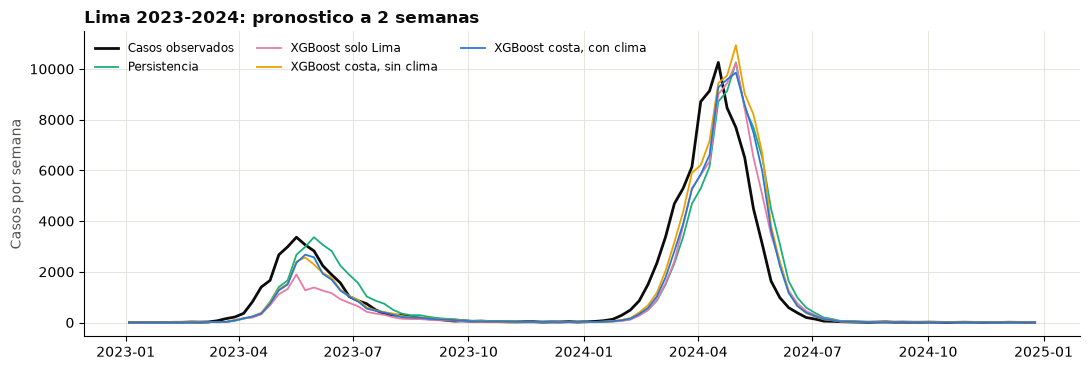

In [9]:
COLORES = {"Persistencia": AQUA, "XGBoost solo Lima": MAGENTA, "XGBoost costa, sin clima": AMARILLO,
           "XGBoost costa, con clima": AZUL}
fig, ax = plt.subplots(figsize=(11, 3.8))
obs = pred_lima[pred_lima["modelo"] == "Persistencia"]
ax.plot(obs["fecha"], obs["casos"], color=TINTA, lw=2, label="Casos observados")
for modelo, color in COLORES.items():
    d = pred_lima[pred_lima["modelo"] == modelo]
    ax.plot(d["fecha"], d["prediccion"], color=color, lw=1.3, label=modelo)
ax.set_ylabel("Casos por semana", color=TINTA_2)
ax.set_title("Lima 2023-2024: pronostico a 2 semanas", loc="left", fontsize=12, fontweight="bold", color=TINTA)
ax.legend(loc="upper left", frameon=False, fontsize=8.5, ncol=3)
estilo(ax)
fig.tight_layout()
fig.savefig(OUT / "lima_pronostico_2023_2024.png", dpi=120)
plt.show()

## Resultados y conclusiones

**1. Cómo emergió.**
- **Explosión en dos años:** Lima pasó de 938 casos en 2022 a 30 735 en 2023 y 87 864 en 2024. Esos dos años son el 97 % de sus casos desde 2010.
- **Concentración en la capital:** el 86 % de los casos de 2023–2024 fue en Lima Metropolitana, sobre todo en Lima norte y este (Comas, San Juan de Lurigancho, Carabayllo, Independencia, Puente Piedra).
- **Nuevos distritos:** 36 de los 79 distritos con casos los tuvieron por primera vez en 2023 o 2024.

**2. El clima acompañó la emergencia.**
- **2023 fue un año de El Niño costero:** el ICEN llegó a 2,9 a mediados de año.
- **Temperatura:** en la zona de los casos fue 1,05 °C mayor que la media de 2010–2022 en las mismas semanas, con picos de +2,5 °C.
- **Humedad:** fue 3,5 puntos mayor que esa media.
- **2024 siguió cálido** (+0,63 °C de media y +0,87 °C entre las semanas 1 y 20).
- El aumento de casos de 2023 empieza cuando sube el ICEN (febrero–marzo). Esto es una **asociación**: no prueba causa, pero coincide con lo que se espera del vector.

**3. ¿Se podía pronosticar? (H3)** MAE con 2 semanas de anticipación, en casos por semana:

| Modelo | 2023 | 2024 |
|---|---|---|
| Persistencia | 247 | 746 |
| XGBoost solo Lima | 291 (R² 0,62) | 606 |
| XGBoost costa, sin clima | 175 | 610 |
| XGBoost costa, con clima | **174** | **604** |

- **Un modelo entrenado solo con Lima falla el año en que emerge el dengue** (2023): es el peor de todos, peor incluso que la persistencia. En 2024 mejora, porque ya aprendió de 2023. **Se confirma H3:** el desempeño es peor en un periodo atípico y sin historia.
- **Entrenar con los departamentos de la costa, que sí conocen el dengue, reduce el error en 2023 un 30 %** frente a la persistencia (174 frente a 247). Aprender el cambio semanal en lugar del nivel permite transferir lo aprendido a un lugar nuevo.
- **El clima casi no cambia el resultado** (174 frente a 175 en 2023), igual que en el resto del país (notebook 11).
- **Todos los modelos se atrasan en el ascenso**, al menos una semana, y ninguno anticipa el único brote nuevo de Lima. En 2023 y 2024 fue un solo episodio largo: 47 y 49 semanas sobre el umbral, que en Lima es muy bajo.

**Implicación para la vigilancia:** en zonas sin historia de dengue conviene usar modelos entrenados con regiones parecidas que sí tienen dengue, y no la historia local. El clima, y en especial El Niño costero, sirve como contexto de alerta temprana. Como predictor semanal agrega poco cuando ya se conocen los casos recientes.
